# Reinforce Agent trained with Monte Carlo Policy Gradien

Implement reinforce pytorch algorithm using policy-based method that optimizes the policy directly without using an action-value funtion, but estimating the weights with gradient ascent. Validate implementation by running the agent in Carpole-v1 and PixelCopter enironments

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd drive/MyDrive/ColabNotebooks/DeepRL/policy_gradient

/content/drive/MyDrive/ColabNotebooks/DeepRL/policy_gradient


In [ ]:
import os
os.chdir('/content/drive/MyDrive/ColabNotebooks/DeepRL/policy_gradient')

## Libraries Instalation

### Virtual Screen packages

In [ ]:
# install virtual screen packages and run, supressing the call display
%%capture
!apt install python-opengl
!apt install ffmpeg
!apt install xvfb
!pip install pyvirtualdisplay
!pip install pyglet==1.5.1

A virtual display is necessary because PyGame Learning Environments require a graphical display to render their visual output. Since Google Colab dies not have grphical, the virtual display provides a simulated screen that these environments can use for rendering. This allows to collect rendered frames for creating videos, even when running the code without a visible display.

In [ ]:
from pyvirtualdisplay import Display

# create a display object which represents a virtual screen,
# making the virtual display invisible with visible=0
virtual_display = Display(visible=0, size=(1400, 900))
virtual_display.start()

### Dependencies

In [ ]:
!pip install git+https://github.com/ntasfi/PyGame-Learning-Environment.git

In [ ]:
!pip install git+https://github.com/simoninithomas/gym-games

In [ ]:
!pip install huggingface_hub imageio-ffmpeg

In [ ]:
!pip install pyyaml

## Import packages

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

import gymnasium as gym
import gym_pygame

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import imageio # generates a replay video
from huggingface_hub import notebook_login

from collections import deque      # double-ended queue, a list-like container that supports fast appends and pops from both ends

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [ ]:
import gymnasium as gym

In [ ]:
def reinforce(policy, optimizer, n_training_episodes, max_t, gamma, print_every, device=device):
  """ Reinforce training algorithm computes the return at each timestep, and it
      reinforcess action on the basis of the rewards that come after the action,
      maximizing the utility function by minimizing min 1−𝜋𝜃(𝑎3|𝑠;𝜃)"""

  # init a double-ended queue ibject to store the total rewards/scores of the last 100 trianing episodes,
  # a deque with maxlen discards the oldes element when a new one is added, keeping onle the most recent, used for running average of the score
  score_deque = deque(maxlen=100)
  scores = []
  # iterate though given number of training episodes collecting the log probabilities
  # of actions and rewards recived used to calculate the policy loss and update the network
  for i_episode in range(1, n_training_episodes + 1):

    ############################## Log Probabilities of Actions ##################

    # init a list to store the log probabilities of the actions taken during the current episode
    saved_log_probs = []
    # init list to store the rewards recived at each steo duting the current episode
    rewards = []
    # reset the environment at the beginning of each episode
    state = env.reset()
    # Handle the tuple output from env.reset()
    if isinstance(state, tuple):
        state = state[0]

    ###################### Single Episode Rewards #####################

    # inner loop that iterates through the steps within a single episode up to max_t steps
    for t in range(max_t):
      # obtain the agent's action and its log probability using the policy network
      action, log_prob = policy.act(state, device) # Pass the device to policy.act
      # append the log probability of the action to the list of saved log probabilities
      saved_log_probs.append(log_prob)
      # take an action in the environment
      next_state, reward, done, _, info = env.step(action) # Unpack 5 values
      # Handle the tuple output from env.step()
      if isinstance(next_state, tuple):
          next_state = next_state[0]
      state = next_state # Update state

      # append the reward to the list of rewards
      rewards.append(reward)
      if done: # episode finished
        break
    # the sum of rewards = total score for current episode is added to both lists
    score_deque.append(sum(rewards)) # Changed from scores_deque.append(sum(rewards))
    scores.append(sum(rewards))
    # init the store of the discounted returns for each time step in current episode
    returns = deque(maxlen=max_t)
    n_steps = len(rewards)
    # compute the discounted returns at each timestep as the sum of the gamma-discounted return
    # at time t, G_t  + the reward at time t, where G_t = r_(t+1) + r_(t+2) + ...
    # the returns at each timestep t can be computed by re-using the computed
    # future returns G_(t+1) to compute the current return G_t = r_(t+1) + gamma*G_(t+1)

    ####################### Reward-to-go for each action ########################

    # slice notation [start:stop:step] slicing an entire sequence with a step of -1,
    # traveses the sequence range(n_steps) backward from the end to the begining
    # with appendleft() the queue returns will hold the returnsin chronologial order
    for t in range(n_steps)[::-1]:
      disc_return_t = (returns[0] if len(returns)>0 else 0)       # the sicounted return from the next step is the first return element of the returns deque if the deques is not empty

    ################### Discounted Return using Dynamic Programming ###############

      returns.appendleft(gamma*disc_return_t + rewards[t])

    # standarized the discounted returns
    eps = np.finfo(np.float32).eps.item()                         # gets the smalles representable float value to guard against division by 0
    returns = torch.tensor(returns).to(device)                               # conver the discounted returns for each timestep into a PyTorh tensor and move to device
    returns = (returns - returns.mean()) / (returns.std() + eps)  # standadize by subtracting the mean and divie by std


    ########################### Policy Loss #######################

    policy_loss = [] # Changed from plocy_loss = []
    # the policy loss for each individual timestep as the negative product
    for log_prob, disc_return in zip(saved_log_probs, returns):
      # append the policy loss for the current step
      policy_loss.append(-log_prob.to(device) * disc_return.to(device)) # Move both to device explicitly
    policy_loss = torch.cat(policy_loss).sum()   # concatenates the list of individual timestep losses into a tensor and sums them up to get the total policy loss for the entire episod

    # minimize the overall loss for the episode
    optimizer.zero_grad()         # clears the gradients
    policy_loss.backward()        # calculate the policy_loss gradient wrt all the parameters of the policy network
    optimizer.step()              # update the parameters of the policy network

    if i_episode % print_every == 0: # Changed from e_pisode
      print('Episode {}\tAverage Score: {:.2f}'.format(i_episode, np.mean(score_deque)))

  # return the list of total reward obstained in each training episode
  return scores

In [ ]:
def evaluate_agent(env, max_steps, n_eval_episodes, policy):
  """ Evaluation of the Reinforce agent method for n_eval_episodes,
      returning average reward and std of reward
      :param env: evaluation environment
      :param n_eval_episodes: number of episode to evaluate the agent
      :param policy: Reinforce agent
  """
  episode_rewards = []
  for episode in range(n_eval_episodes):
    state = env.reset()
    # handle the tuple output from env.reset()
    if isinstance(state, tuple):
        state = state[0]
    step = 0
    done = False
    total_rewards_ep = 0

    for step in range(max_steps):
      action, _ = policy.act(state, device)
      new_state, reward, terminated, truncated, info = env.step(action) # Unpack 5 values
      done = terminated or truncated # determine if episode is done
      # handle the tuple output from env.step()
      if isinstance(new_state, tuple):
          new_state = new_state[0]
      state = new_state # update state

      total_rewards_ep += reward

      if done:
        break
    episode_rewards.append(total_rewards_ep)
  mean_reward = np.mean(episode_rewards)
  std_reward = np.std(episode_rewards)

  return mean_reward, std_reward

In [ ]:
import cv2
import imageio
import numpy as np
import gymnasium as gym

def record_video(env, policy, out_path, fps=30, max_steps=500, resize_to=(256, 256)):
    images = []
    obs, info = env.reset()   # unpack reset tuple
    done = False
    step = 0

    img = env.render()
    if img is not None:
        if resize_to:
            img = cv2.resize(img, resize_to, interpolation=cv2.INTER_NEAREST)
        images.append(img)

    while not done and step < max_steps:
        action, _ = policy.act(obs, device)   # trained policy
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        step += 1

        img = env.render()
        if img is not None:
            if resize_to:
                img = cv2.resize(img, resize_to, interpolation=cv2.INTER_NEAREST)
            images.append(img)


    if images:
        # save to mp4 since Hugging Face expects .mp4 not .gif)
        imageio.mimsave(out_path, images, fps=fps, macro_block_size=None)
        print(f"Video saved to {out_path}")
    else:
        print("No frames collected. Check render_mode.")


In [ ]:
from huggingface_hub import HfApi, snapshot_download
from huggingface_hub.repocard import metadata_eval_result, metadata_save

from pathlib import Path
import datetime
import json
import imageio

import tempfile

import os

notebook_login()


def push_to_hub(repo_id,
                model,
                hyperparameters,
                eval_env,
                video_fps=30,
                rotate_deg=0
                ):
  """
  Evaluate, Generate a video and Upload a model to Hugging Face Hub.
  This method does the complete pipeline:
  - It evaluates the model
  - It generates the model card
  - It generates a replay video of the agent
  - It pushes everything to the Hub

  :param repo_id: repo_id: id of the model repository from the Hugging Face Hub
  :param model: the pytorch model we want to save
  :param hyperparameters: training hyperparameters
  :param eval_env: evaluation environment
  :param video_fps: how many frame per seconds to record our video replay
  """

  _, repo_name = repo_id.split("/")
  api = HfApi()

  # Step 1: Create the repo
  repo_url = api.create_repo(
        repo_id=repo_id,
        exist_ok=True,
  )

  with tempfile.TemporaryDirectory() as tmpdirname:
    local_directory = Path(tmpdirname)

    # Step 2: Save the model
    torch.save(model, local_directory / "model.pt")

    # Step 3: Save the hyperparameters to JSON, converting numpy integers to standard integers for JSON serialization
    serializable_hyperparameters = {k: int(v) if isinstance(v, np.integer) else v for k, v in hyperparameters.items()}
    with open(local_directory / "hyperparameters.json", "w") as outfile:
      json.dump(serializable_hyperparameters, outfile)

    # Step 4: Evaluate the model and build JSON
    mean_reward, std_reward = evaluate_agent(eval_env,
                                            hyperparameters["max_t"],
                                            hyperparameters["n_evaluation_episodes"],
                                            model)
    # Get datetime
    eval_datetime = datetime.datetime.now()
    eval_form_datetime = eval_datetime.isoformat()

    evaluate_data = {
          "env_id": hyperparameters["env_id"],
          "mean_reward": mean_reward,
          "n_evaluation_episodes": hyperparameters["n_evaluation_episodes"],
          "eval_datetime": eval_form_datetime,
    }

    # Write a JSON file
    with open(local_directory / "results.json", "w") as outfile:
        json.dump(evaluate_data, outfile)

    # Step 5: Create the model card
    env_name = hyperparameters["env_id"]

    metadata = {}
    metadata["tags"] = [
          env_name,
          "reinforce",
          "reinforcement-learning",
          "custom-implementation",
          "deep-rl-class"
      ]

    # add metrics
    eval = metadata_eval_result(
        model_pretty_name=repo_name,
        task_pretty_name="reinforcement-learning",
        task_id="reinforcement-learning",
        metrics_pretty_name="mean_reward",
        metrics_id="mean_reward",
        metrics_value=f"{mean_reward:.2f} +/- {std_reward:.2f}",
        dataset_pretty_name=env_name,
        dataset_id=env_name,
      )

    # Merges both dictionaries
    metadata = {**metadata, **eval}

    model_card = f"""
  # **Reinforce** Agent playing **{env_id}**
  This is a trained model of a **Reinforce** agent playing **{env_id}**
  """

    readme_path = local_directory / "README.md"
    readme = ""
    if readme_path.exists():
        with readme_path.open("r", encoding="utf8") as f:
          readme = f.read()
    else:
      readme = model_card

    with readme_path.open("w", encoding="utf-8") as f:
      f.write(readme)

    # Save our metrics to Readme metadata
    metadata_save(readme_path, metadata)

    # Step 6: Record a video
    record_video(
        env=eval_env,
        policy=model,
        out_path= local_directory / "replay.mp4",   # save as mp4 for Hugging Face
        fps=30,
        rotate_deg=rotate_deg
)

    # Step 7. Push everything to the Hub
    api.upload_folder(
          repo_id=repo_id,
          folder_path=local_directory,
          path_in_repo=".",
    )

    print(f"Model is pushed to the Hub. You can view the model here: {repo_url}")

## <font size=16>**REINFORCE algorithm**</font>

REINFORCE is the simplest implementation of a policy gradient method, which maximizes the probability of an action * observed reward, after taking that action, s.t. each action's probability for given state is adjusted according to the size of the observed reward.

In [ ]:
!pip install gymnasium torch

In [ ]:
import torch
import gymnasium as gym
import numpy as np

import matplotlib.pyplot as plt

### Policy Network

A neural network which accept state vectors as inputs and produce a discreate probability distribution over the possible actions that will be executed in the environment

In [ ]:
l1 = 4
l2 = 168
l3 = 2

model = torch.nn.Sequential(
    torch.nn.Linear(l1, l2),
    torch.nn.LeakyReLU(),    # leaky RELU performs beterrer empirically
    torch.nn.Linear(l2, l3),
    torch.nn.Softmax(dim=1) # squashes an array of numbers into the range of 0 to 1 and makes them all sum to 1
)

learning_rate = 0.0009
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [ ]:
env_id = "CartPole-v1"
env = gym.make(env_id)
eval_env = gym.make(env_id, render_mode='rgb_array')

In [ ]:
# get the initial state from the environment with reset() method returns a tuple, where the first element is the initial observation.
state0, info = env.reset()

# display the initial state
print("CartPole initial state:", state0)
print("\nwith the following observations")
print(f"\ncart position: {state0[0]},\ncart velocity: {state0[1]},\npole angle {state0[2]},\npole angular velocity:{state0[3]}")

CartPole initial state: [ 0.01822351 -0.0250512   0.03537882  0.00817628]

with the following observations

cart position: 0.018223511055111885,
cart velocity: -0.02505119889974594,
pole angle 0.035378821194171906,
pole angular velocity:0.008176282048225403


In [ ]:
# get the initial state, pass it to the model, using the policy network to sample an action and take a step in the environment

# ensure state0 is a tensor, has a batch dimension, and is on the correct device
state0_tensor = torch.from_numpy(state0).float().unsqueeze(0).to(device) # add unsqueeze(0) and to(device)
pred = model(state0_tensor)
action = np.random.choice(np.array([0, 1]), p=pred.data.numpy()[0])      # corrected np.array call and added [0] to pred.data.numpy()
state1, reward, terminated, truncated, info = env.step(action)           # gymnasium unpacks 5 values instead of the network 4 observations
done = terminated or truncated                                           # determine if episode is done

print("""CartPole state after agent taking an action from the
probability distribution poduced by the policy network:\n""", state1)
print("The environment responds to the action by producing a new state and a reward:", reward)

CartPole state after agent taking an action from the
probability distribution poduced by the policy network:
 [-0.01767902 -0.02453668  0.06590486  0.14612478]
The environment responds to the action by producing a new state and a reward: 1.0


The environment respond to the action by producing a new state and a reward, values stored in a `state` array and `actions` array for when the model would be updated after the spisode ends. The new state is pluged into the model and a state and a reward are produced, stored and repeat until the episode ends - pole falls, max number of episode steps is taken.

### Training

Training the policy network by updateing the parameters to minimize the objective, los, function:

1. Calculate the probability of the action actually taken at each time step
2. Multiply the probability by the discounted return, the sum of rewards
3. Use this probability-weighted return to backpropagate and minimize the loss

#### Help Functions

In [ ]:
# compute the discount rewards
def discount_rewards(rewards, gamma=0.99):
  """ Compute the discounted rewards given an array of rewards with
      length, te length of episode, turning the linear sequence of
      rewards into an exponentially decaying sequence of rewards,
      and dividing it by the maximum value to normalize the values
      to the interval [0, 1] """

  len_rewards = len(rewards)
  disc_return = torch.pow(gamma, torch.arange(len_rewards).float())*rewards

  # normalization step imporves lreaning efficiency and stability as it keeps
  # the return value within the same range no matter how big the raw return is,
  # and so the gradient changes are less than orders of magnitutde
  norm_disc_return /= disc_return.max()

  return norm_disc_return

In [ ]:
# define the loss function
def loss_fn(preds, r):
  """ loss function the negative log-probability of the action given the state,
      scaled by the reward returns"""
  return -1*torch.sum(r*torch.log(preds))

#### Training loop

Episode 0, length 18, loss 0.3704
Episode 50, length 96, loss 0.7845
Episode 100, length 141, loss -3.8945
Episode 150, length 262, loss 6.5904
Episode 200, length 500, loss 5.9963
Episode 250, length 500, loss 8.7429
Episode 300, length 500, loss -10.9026
Episode 350, length 500, loss -9.4952
Episode 400, length 500, loss 12.2855
Episode 450, length 500, loss 1.6925


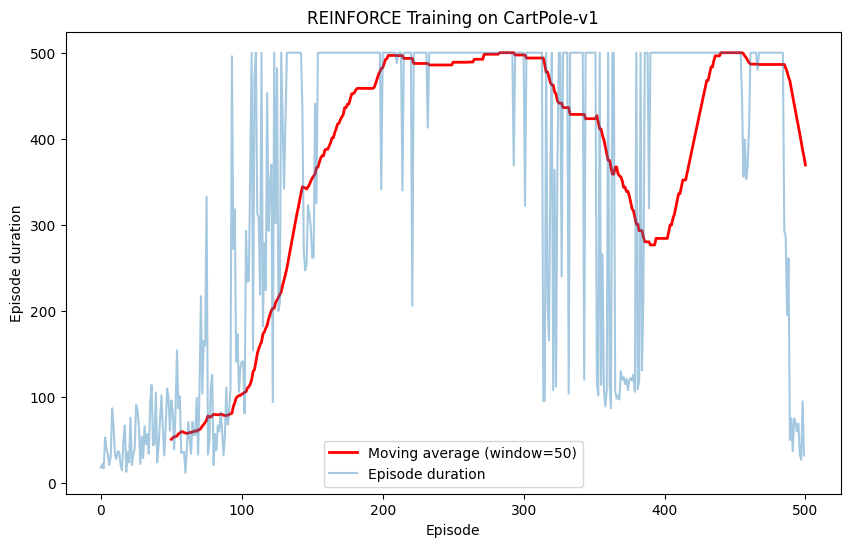

In [ ]:
# --- Policy Network ---
l1 = 4
l2 = 168
l3 = 2

model = torch.nn.Sequential(
    torch.nn.Linear(l1, l2), # expects a batch of states shaped [batch_size, 4]
    torch.nn.LeakyReLU(),
    torch.nn.Linear(l2, l3),
    torch.nn.Softmax(dim=1) # expects batch dimention 0
)

learning_rate = 0.005 # REINFORCE with Adam works better in the 1e-2 to 1e-3 range, too small the gradients vanish, too large → unstable
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

env_id = "CartPole-v1"
env = gym.make(env_id)

# --- Helper Functions ---
def discount_rewards(rewards, gamma=0.99):
  """ Normalize across an entire batch of episodes, not per episode."""
  R = 0
  discounted = []
  for r in reversed(rewards):
      R = r + gamma * R
      discounted.insert(0, R)
  discounted = torch.tensor(discounted, dtype=torch.float32)
  discounted_return = (discounted - discounted.mean()) / (discounted.std() + 1e-8)
  return discounted_return

def loss_fn(log_probs, discounted_rewards):
  """ Multiply each log_prob[t] by its discounted return G_t """
  #the gradient direction is noisy and doesn't reflect which action were good or bad.
  return -1 * torch.sum(torch.stack(log_probs)*discounted_rewards)

def moving_average(data, window_size=50):
    """Compute simple moving average with given window size."""
    # convolution "slides" one sequence, a kernel, [1/window_size, 1/window_size, ..., 1/window_size] over the
    # data and computes a weighted sum at each position, thus taking the averate of the last window_size values
    # mode controls how edges are handles, valid only returns positions where kernel fully fits without padding
    return np.convolve(data, np.ones(window_size)/window_size, mode="valid")


# --- Training ---
MAX_DUR = 500
n_episodes = 500   # total episodes
durations = []     # track episode length for plotting

for episode in range(n_episodes):
    curr_state, info = env.reset()
    rewards = []
    log_probs = []

    for t in range(MAX_DUR):
        # before feeding the state to the model convert state into tensor adding batch dimension [1, 4]
        state_tensor = torch.from_numpy(curr_state).float().unsqueeze(0)
        # state_tensor.shape = [batch_size, features]
        # forward pass
        #returns act_pron.shape=[batch_size, action_probabilities], probabilies for 2 actions, right and left
        act_prob = model(state_tensor)
        # sample the action probability distribution
        action = np.random.choice(np.array([0,1]), p=act_prob.detach().numpy()[0])
        # save log probability for chosen action
        # remove the leading demension, batch_size, so that the action probabilites can be indexed directly
        log_probs.append(torch.log(act_prob.squeeze(0)[action]))  # act_prob.squeeze(0) hape becomes [2], the probability of sampled action 0 or 1
                                                                  # can avoid squeezing if index the batch dim, torch.log(act_prob[0, action]
        # get the state, reward from the environment, gymnasium puts out 5 tuple
        next_state, reward, terminated, truncated, info = env.step(action)
        rewards.append(reward)

        curr_state = next_state
        if terminated or truncated:
            break

    # after each episode store its length, compute discounted return, loss and optimaize

    # store duration
    durations.append(t + 1)

    # compute discounted return
    rewards = torch.tensor(rewards, dtype=torch.float32)
    discounted = discount_rewards(rewards)

    # policy gradient loss
    loss = loss_fn(log_probs, discounted)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if episode % 50 == 0:
        print(f"Episode {episode}, length {t+1}, loss {loss.item():.4f}")

# --- Plot Training Progress ---
plt.figure(figsize=(10,6))
plt.plot(range(50, n_episodes+1), moving_average(durations, 50),
         color="red", linewidth=2, label="Moving average (window=50)")
plt.plot(durations, alpha=0.4, label="Episode duration")
plt.xlabel("Episode")
plt.ylabel("Episode duration")
plt.title("REINFORCE Training on CartPole-v1")
plt.legend()
plt.show()


NB: OpenAI docs say that the game is considred "solved" if the agent can play an episode beyond 200 time steps.

**To Do:** Improving implementation for more complex environments changing the network to Convolutional Neural Network to handle frames as observation

# <font size="16">**CartPole-v1**</font>

A pole is attached to a cart, which moves along a fritionless track. The pole is placed upright and the goa is to balance the pole by applying forces when mooving to the left and right direction

In [ ]:
env_id = "CartPole-v1"

# Create the env
env = gym.make(env_id)

# create the evaluation env and configiure it to return RGB array frames when env.render() called
eval_env = gym.make(env_id, render_mode='rgb_array')

# Get the state space and action space
s_size = env.observation_space.shape[0]
a_size = env.action_space.n

In [ ]:
print("_____OBSERVATION SPACE_____ \n")
print("The State Space is: ", s_size)
print("Sample random observation", env.observation_space.sample())

_____OBSERVATION SPACE_____ 

The State Space is:  4
Sample random observation [ 2.7302406  -0.05002273 -0.00465203 -2.205713  ]


In [ ]:
print("\n _____ACTION SPACE_____ \n")
print("The Action Space is: ", a_size)
print("Action Space Sample", env.action_space.sample())


 _____ACTION SPACE_____ 

The Action Space is:  2
Action Space Sample 0


/usr/local/lib/python3.12/dist-packages/pygame/pkgdata.py:25: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import resource_stream, resource_exists
/usr/local/lib/python3.12/dist-packages/pkg_resources/__init__.py:3154: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace('google')`.
Implementing implicit namespace packages (as specified in PEP 420) is preferred to `pkg_resources.declare_namespace`. See https://setuptools.pypa.io/en/latest/references/keywords.html#keyword-namespace-packages
  declare_namespace(pkg)
/usr/local/lib/python3.12/dist-packages/pkg_resources/__init__.py:3154: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace('google.cloud')`.
Implementing implicit namespace packages (as specified in PEP 420) is preferred to `pkg_resources.declare_namespace`. See https://setuptools.pypa.io/en/latest/references/keywords.html#keyword-namespace-pa

Shape of the RGB array: (400, 600, 3)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


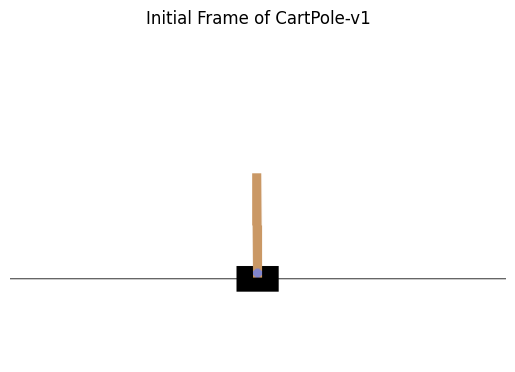

Shape of the RGB array after a step: (400, 600, 3)


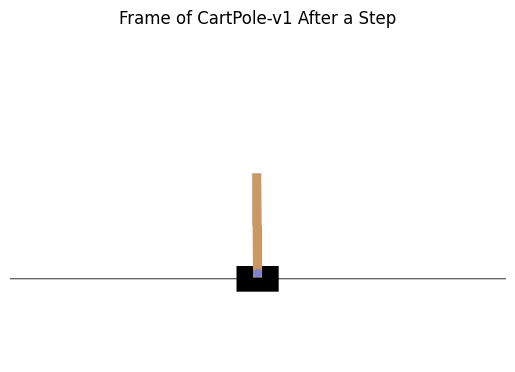

In [ ]:
# test retrieving visual state as an RGB array with render_mode='rgb_array'
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Create the environment with rgb_array rendering
env = gym.make("CartPole-v1", render_mode="rgb_array")

# Reset the environment to get the initial observation
observation, info = env.reset()

# Render the environment to get the initial frame as an RGB array
rgb_array = env.render()

# The rgb_array will be a NumPy array with shape (height, width, 3)
# You can then process this array or display it using a library like Matplotlib
print(f"Shape of the RGB array: {rgb_array.shape}")

# Display the image (optional)
plt.imshow(rgb_array)
plt.title("Initial Frame of CartPole-v1")
plt.axis('off') # hide axes for cleaner image
plt.show()

# Take a step in the environment and render again
action = env.action_space.sample() # Take a random action
observation, reward, terminated, truncated, info = env.step(action)
rgb_array_after_step = env.render()

print(f"Shape of the RGB array after a step: {rgb_array_after_step.shape}")

# Display the image after a step (optional)
plt.imshow(rgb_array_after_step)
plt.title("Frame of CartPole-v1 After a Step")
plt.axis('off')
plt.show()

# Close the environment when done
env.close()

## Reinforce Architecture

Implementation based on:
- [PyTorch official Reinforcement Learning example](https://github.com/pytorch/examples/blob/main/reinforcement_learning/reinforce.py)
- [Udacity Reinforce](https://github.com/udacity/deep-reinforcement-learning/blob/master/reinforce/REINFORCE.ipynb)

Two fully connected layers, using ReLU, f(x) = max(0, x) as activation of FC1 and Softmax, Softmax(z) = e^z/∑(e^z) to output a probability distiribution over actions

<img src="https://huggingface.co/datasets/huggingface-deep-rl-course/course-images/resolve/main/en/unit6/reinforce.png" alt="Reinforce"/>

In [ ]:
class Policy(nn.Module):
  def __init__(self, s_size, a_size, h_size):
    """ Class constructor which calls the constructor of the parent class nn.Module
        which sets up behind-the-scene functionality. It initalizes two fully connected layers
    """
    super(Policy, self).__init__()
    self.fc1 = nn.Linear(s_size, h_size)
    self.fc2 = nn.Linear(h_size, a_size)

  def forward(self, x):
    """ Defines the forward pass: takes in the input state x, passes it though
        the first fuuly connected layer, applice th ReLU activateion then passes
        it the result through the second fully connected layer, and applies the
        Softmax function to get a probability distribution over the actions
    """
    x = F.relu(self.fc1(x))
    #print(f"device of tensors inside forward pass, mat1: {x.device}, mat2: {self.fc1.weight.device}")
    x = self.fc2(x)
    # convert raw scores into a probability distribution
    return F.softmax(x, dim=1) # softmax applied across the action dimension,
                               # second dim of the input tensor [batch_size, a_size]
                               # [1, # possible actions]

  def act(self, state, device): # Accept the device argument
    """I takes the state as an input and returns an actiona and its probabillity.
       It sample action from the probability distribution over actions """
    state = torch.from_numpy(state).float().unsqueeze(0).to(device)
    # a tensor containing the probabilities for each action
    probs = self.forward(state)
    # create a categotical probability distribution object uing Categotical class
    # from torch.distributions, which is a discrete probability distribution that
    # describes the probability of obtaining one of a finite number of possible actions

    m = torch.distributions.Categorical(probs)  # m = Categorical(probs)
    # sample an action from the probability distribution over actions
    action = m.sample()
    # calculating the log probability of given action
    return action.item(), m.log_prob(action)

### Train

Train in CartPole environment with state space of 4 observations - car position, car velocity, pole angle, pole angular velocity, and action space of 2 -move left or move right. Difference in environment complexity necessitate changes in teh policy network architecture and  training hyperparameters

REINFORCE is very high variance; even if training shows good scores, the learned policy may not generalize well. If too aggressive learning rate policies swing around instead of stabilizing. If hidden layer too small can cause unstable behaviour, no discounting makes return estimates very noisy in long episodes. Adding Entropy Regularization ecourages exploration and avoids collapsing too early. Instead of using raw returns, subtract a baseline to reduce variance

In [ ]:
cartpole_hyperparameters = {
    "h_size": 64,                 # increase hiden layer size from 16
    "n_training_episodes": 1500,
    "n_evaluation_episodes": 50,  # since CartPloe is stochastic, estimate of performance has high variance
    "max_t": 500,                 # CoartPole-v1 has a hard-coded max episode length of 500 steps
    "gamma": 0.99,                # use discount < 1 instead of 1.00 no discount of future rewards
    "lr": 1e-3,                   # instead of 1e-2
    "env_id": env_id,
    "state_space": s_size,
    "action_space": a_size,
}

In [ ]:
# create polocy
cartpole_policy = Policy(cartpole_hyperparameters["state_space"], cartpole_hyperparameters["action_space"], cartpole_hyperparameters["h_size"]).to(device)
cartpole_optimizer = optim.Adam(cartpole_policy.parameters(), lr=cartpole_hyperparameters["lr"])

In [ ]:
print(next(cartpole_policy.parameters()).device)

cuda:0


In [ ]:
scores = reinforce(cartpole_policy,
                   cartpole_optimizer,
                   cartpole_hyperparameters["n_training_episodes"],
                   cartpole_hyperparameters["max_t"],
                   cartpole_hyperparameters["gamma"],
                   100)

Episode 100	Average Score: 25.04
Episode 200	Average Score: 31.86
Episode 300	Average Score: 48.97
Episode 400	Average Score: 86.94
Episode 500	Average Score: 184.36
Episode 600	Average Score: 271.90
Episode 700	Average Score: 382.50
Episode 800	Average Score: 436.12
Episode 900	Average Score: 428.84
Episode 1000	Average Score: 461.85
Episode 1100	Average Score: 493.27
Episode 1200	Average Score: 489.90
Episode 1300	Average Score: 491.69
Episode 1400	Average Score: 483.63
Episode 1500	Average Score: 483.39


### Evaluation

In [ ]:
evaluate_agent(eval_env,
               cartpole_hyperparameters["max_t"],
               cartpole_hyperparameters["n_evaluation_episodes"],
               cartpole_policy)

(np.float64(492.66), np.float64(51.379999999999995))

In [ ]:
# save trained model checkpoint
torch.save({
    "model_state_dict": cartpole_policy.state_dict(),
    "optimizer_state_dict": cartpole_optimizer.state_dict(),
    "hyperparameters": cartpole_hyperparameters
}, "cartpole_checkpoint.pth")

# reload
#checkpoint = torch.load("cartpole_checkpoint.pth")
#cartpole_policy.load_state_dict(checkpoint["model_state_dict"])
#cartpole_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
#cartpole_hyperparameters = checkpoint["hyperparameters"]

In [ ]:
# save hyperparameters as JSON
import json

with open("cartpole_hyperparameters.json", "w") as f:
  json.dupm(cartpole_hyperparameters, f, indent=4)

# load
#with open("cartpole_hyperparameters.json", "r") as f:
  #cartpole_hyperparameters = json.load(f)

In [ ]:
# save hyperparameters as YAML, easier to read and edit by hand
import yaml

# save
with open("cartpole_hyperparameters.yaml", "w") as f:
    yaml.dump(cartpole_hyperparameters, f)

# load
#with open("cartpole_hyperparameters.yaml", "r") as f:
    #cartpole_hyperparameters  = yaml.safe_load(f)

## Video

In [ ]:
import imageio
import numpy as np
import gymnasium as gym

def record_video(env, policy, out_path, fps=30, max_steps=500):
    images = []
    obs, info = env.reset()   # unpack reset tuple
    done = False
    step = 0

    img = env.render()
    if img is not None:
        images.append(img)

    while not done and step < max_steps:
        action, _ = policy.act(obs, device)   # trained policy
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        step += 1

        img = env.render()
        if img is not None:
            images.append(img)

    if images:
        print(f"Collected {len(images)} frames.")
        if len(images) > 0:
            print(f"Shape of first frame: {np.array(images[0]).shape}")
            if len(images) > 1:
                print(f"Shape of second frame: {np.array(images[1]).shape}")

        # save to mp4 since Hugging Face expects .mp4 not .gif)
        try:
            imageio.mimsave(out_path, images, fps=fps, macro_block_size=None)
            print(f"Video saved to {out_path}")
        except Exception as e:
            print(f"Error saving video: {e}")
            print("Attempting to save frames individually for inspection...")
            for i, frame in enumerate(images):
                try:
                    imageio.imwrite(f"{out_path}_frame_{i}.png", frame)
                except Exception as frame_e:
                    print(f"Could not save frame {i}: {frame_e}")

    else:
        print("No frames collected. Check render_mode.")

In [ ]:
from IPython.display import Video

# record and display video
eval_env = gym.make("CartPole-v1", render_mode="rgb_array")

record_video(
    env=eval_env,
    policy=cartpole_policy,
    out_path="replay.mp4",   # save as mp4 for Hugging Face
    fps=30
)

# Display the video inline
Video("replay.mp4", embed=True)


🎥 Video saved to replay.mp4


## Push to Hub

In [ ]:
eval_env = gym.make("CartPole-v1", render_mode="rgb_array")

In [ ]:
repo_id = "elliemci/Reinforce-CartPole"  # repo id {username/Reinforce-{model-id}}

push_to_hub(repo_id,
            cartpole_policy,
            cartpole_hyperparameters,
            eval_env)
            #video_fps=30)

🎥 Video saved to /tmp/tmpimx_shb9/replay.mp4


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmpimx_shb9/model.pt   : 100%|##########| 5.13kB / 5.13kB            

Model is pushed to the Hub. You can view the model here: https://huggingface.co/elliemci/Reinforce-CartPole


# <font size="16">**PixelCopter**</font>

A side-scrolling game where the aagent must successfully namigate through a cavern. For each vertical block passes through it gains reward of +1. Each time a terminal is state reached it gains a reward of -1.

Since instalation of gym-games, the wrapper which supposed to register the Pixel-PLE-v0 fails, resort to manual registration for Pixelcopter

In [ ]:
import numpy

import gymnasium as gym

from gymnasium.envs.registration import register
from ple import PLE
from ple.games.pixelcopter import Pixelcopter

class PixelcopterEnv(gym.Env):
  """ This class inherits from gimansium.Env and implements the methods required
      for Gymnasium interface, making the Pixelcopter game compatible with
      reinforcement learning framework. """

  # define the supported rendering modes and rendering frames per second
  metadata = {"render_modes": ["human", "rgb_array"], "render_fps": 30}

  def __init__(self, render_mode=None):
    """ Initializes the Pixelcopter game using PLE, gets the available actions,
        defines the action space as discrete, defines the observation space as
        a Box, continuis space, stores the requested render_mode."""
    super().__init__()
    self.game = Pixelcopter()
    self.p = PLE(self.game, fps=30, display_screen=(render_mode=="human"))
    self.action_set = self.p.getActionSet()
    self.action_space = gym.spaces.Discrete(len(self.action_set))
    self.observation_space = gym.spaces.Box(
        low=-np.inf, high=np.inf,
        shape=(len(self.p.getGameState()),), dtype=np.float32
      )
    self.render_mode = render_mode

  def reset(self, seed=None, options=None):
    """ Resets the environment to new initial state. Initializes and resets
        the underling PLE game and retirns the initial onservation/ game state
        and an empty info dictionary as required by the Gimnasium API. """
    super().reset(seed=seed)
    self.p.init()
    self.p.reset_game()
    obs = np.array(list(self.p.getGameState().values()), dtype=np.float32)
    return obs, {}

  def step(self, action):
    """ It maps the discrete action index to the actual action used by PLE game.
        It advances the game state and returns the next observation, the recived
        reward, and either done or truncated flag, and an infor dictionary."""
    reward = self.p.act(self.action_set[action])
    obs = np.array(list(self.p.getGameState().values()), dtype=np.float32)
    done = self.p.game_over()
    return obs, reward, done, False, {}

  def render(self):
    """ Renders the environment based on the rendering_mode"""
    if self.render_mode == "human":
        return                       # PLE handles its own window, displaying the game
    elif self.render_mode == "rgb_array":
        return self.p.getScreenRGB() # returns the current screen as RGB NumPy array

  def close(self):
    """ Cleans up the environment resources by quiting PLE game """
    self.p.quit()

# Register PixelCopterEnv with Gymnasium environment registry, which alows creating an instance of the environment with gym.make()
register(
  id="Pixelcopter-PLE-v0",
  entry_point=PixelcopterEnv,
  max_episode_steps=1000, # set the max number of steps for each episode before it gets truncated
)

In [ ]:
env = gym.make("Pixelcopter-PLE-v0", render_mode="rgb_array")
obs, info = env.reset()
print("Observation shape:", obs.shape)
obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
print("Step -> reward:", reward, "terminated:", terminated)


Observation shape: (7,)
Step -> reward: 0.0 terminated: False


In [ ]:
print([env for env in gym.envs.registry.keys() if "Pixelcopter" in env])

['Pixelcopter-PLE-v0']


In [ ]:
env_id = "Pixelcopter-PLE-v0"
env = gym.make(env_id)
eval_env = gym.make(env_id)

s_size = env.observation_space.shape[0]
a_size = env.action_space.n

In [ ]:
print("_____OBSERVATION SPACE_____ \n")
print("The State Space is: ", s_size)
print("Sample observation", env.observation_space.sample())

_____OBSERVATION SPACE_____ 

The State Space is:  7
Sample observation [ 1.3814155   0.19620378 -0.9240579  -0.7649233   0.80320626  0.5290999
 -0.6954411 ]


In [ ]:
print("\n _____ACTION SPACE_____ \n")
print("The Action Space is: ", a_size)
print("Action Space Sample", env.action_space.sample())


 _____ACTION SPACE_____ 

The Action Space is:  2
Action Space Sample 1


In [ ]:
class Policy(nn.Module):
    def __init__(self, s_size, a_size, h_size):
        super(Policy, self).__init__()
        self.fc1 = nn.Linear(s_size, h_size)
        self.fc2 = nn.Linear(h_size, h_size*2)
        self.fc3 = nn.Linear(h_size*2, a_size)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return F.softmax(x, dim=1)

    def act(self, state, device):
        state = torch.from_numpy(state).float().unsqueeze(0).to(device)
        probs = self.forward(state)
        m = Categorical(probs)
        action = m.sample()
        return action.item(), m.log_prob(action)

In [ ]:
pixelcopter_hyperparameters = {
    "h_size": 64,
    "n_training_episodes": 10000,
    "n_evaluation_episodes": 10,
    "max_t": 10000,
    "gamma": 0.99,
    "lr": 1e-4,
    "env_id": env_id,
    "state_space": s_size,
    "action_space": a_size,
}

In [ ]:
# Create policy and place it to the device; torch.manual_seed(50)
pixelcopter_policy = Policy(pixelcopter_hyperparameters["state_space"], pixelcopter_hyperparameters["action_space"], pixelcopter_hyperparameters["h_size"]).to(device)
pixelcopter_optimizer = optim.Adam(pixelcopter_policy.parameters(), lr=pixelcopter_hyperparameters["lr"])

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
scores = reinforce(pixelcopter_policy,
                   pixelcopter_optimizer,
                   pixelcopter_hyperparameters["n_training_episodes"],
                   pixelcopter_hyperparameters["max_t"],
                   pixelcopter_hyperparameters["gamma"],
                   1000)

Episode 1000	Average Score: 4.71
Episode 2000	Average Score: 7.81
Episode 3000	Average Score: 9.77
Episode 4000	Average Score: 10.73
Episode 5000	Average Score: 13.25
Episode 6000	Average Score: 16.10
Episode 7000	Average Score: 12.97
Episode 8000	Average Score: 11.27
Episode 9000	Average Score: 18.67
Episode 10000	Average Score: 16.08


In [ ]:
evaluate_agent(eval_env,
               pixelcopter_hyperparameters["max_t"],
               pixelcopter_hyperparameters["n_evaluation_episodes"],
               pixelcopter_policy)

(np.float64(15.0), np.float64(7.899367063252599))

In [ ]:
# load the model to continuing training

# new since PyTorch >2.6 the weight_only=True block arbitrary python objests inside the checkpoint
checkpoint = torch.load("pixelcopter_checkpoint.pth", map_location=device, weights_only=False)

# Recreate model & optimizer with the same architecture
pixelcopter_policy = Policy(
    s_size=checkpoint["hyperparameters"]["state_space"],
    a_size=checkpoint["hyperparameters"]["action_space"],
    h_size=checkpoint["hyperparameters"]["h_size"],
).to(device)

pixelcopter_optimizer = torch.optim.Adam(
    pixelcopter_policy.parameters(),
    lr=checkpoint["hyperparameters"]["lr"]
)

# Load weights
pixelcopter_policy.load_state_dict(checkpoint["model_state_dict"])
pixelcopter_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
pixelcopter_hyperparameters = checkpoint["hyperparameters"]

# if changed lr, re-init optimizer
#pixelcopter_optimizer = torch.optim.Adam(
    #pixelcopter_policy.parameters(),
    #lr=pixelcopter_hyperparameters["lr"]
#)

In [ ]:
scores = reinforce(pixelcopter_policy,
                   pixelcopter_optimizer,
                   pixelcopter_hyperparameters["n_training_episodes"],
                   pixelcopter_hyperparameters["max_t"],
                   pixelcopter_hyperparameters["gamma"],
                   1000)

Episode 1000	Average Score: 18.55
Episode 2000	Average Score: 19.51
Episode 3000	Average Score: 19.09
Episode 4000	Average Score: 18.70
Episode 5000	Average Score: 16.51
Episode 6000	Average Score: 19.37
Episode 7000	Average Score: 24.77
Episode 8000	Average Score: 27.30
Episode 9000	Average Score: 14.73
Episode 10000	Average Score: 21.33


In [ ]:
evaluate_agent(eval_env,
               pixelcopter_hyperparameters["max_t"],
               pixelcopter_hyperparameters["n_evaluation_episodes"],
               pixelcopter_policy)

(np.float64(19.9), np.float64(16.04026184324932))

In [ ]:
# save trained model checkpoint
torch.save({
    "model_state_dict": pixelcopter_policy.state_dict(),
    "optimizer_state_dict": pixelcopter_optimizer.state_dict(),
    "hyperparameters": pixelcopter_hyperparameters
}, "pixelcopter_checkpoint.pth")

In [ ]:
import cv2
import imageio
import numpy as np

def record_video(env, policy, out_path,
                 fps=30, max_steps=2000,
                 resize_to=(256, 256),
                 rotate_deg=0,
                 seed=None):
    """
    Record a rollout and save to out_path.
    seed: integer or None. If given, sets the environment seed at reset.
    """

    if rotate_deg not in (0, 90, 180, 270):
        raise ValueError("rotate_deg must be one of (0, 90, 180, 270)")

    rot_flag = None
    if rotate_deg == 90:
        rot_flag = cv2.ROTATE_90_COUNTERCLOCKWISE
    elif rotate_deg == 180:
        rot_flag = cv2.ROTATE_180
    elif rotate_deg == 270:
        rot_flag = cv2.ROTATE_90_CLOCKWISE

    # helper for processing frames
    def process_frame(img):
        if img is None:
            return None
        if not isinstance(img, np.ndarray):
            img = np.asarray(img)
        if img.ndim == 2:  # grayscale
            img = np.stack([img, img, img], axis=-1)
        if img.shape[-1] == 4:  # drop alpha
            img = img[..., :3]
        if img.dtype != np.uint8:
            img = img.astype(np.float32)
            mn, mx = img.min(), img.max()
            if mx - mn > 1e-8:
                img = 255.0 * (img - mn) / (mx - mn)
            img = np.clip(img, 0, 255).astype(np.uint8)
        if resize_to:
            img = cv2.resize(img, resize_to, interpolation=cv2.INTER_NEAREST)
        if rot_flag is not None:
            img = cv2.rotate(img, rot_flag)
        return img

    # reset with seed
    obs, info = env.reset(seed=seed)
    done = False
    step = 0
    images = []

    # first frame
    img = env.render()
    pf = process_frame(img)
    if pf is not None:
        images.append(pf)

    while not done and step < max_steps:
        action, _ = policy.act(obs, device)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        step += 1

        img = env.render()
        pf = process_frame(img)
        if pf is not None:
            images.append(pf)

    if images:
        imageio.mimsave(out_path, images, fps=fps, macro_block_size=None)
        print(f"Video saved to {out_path} — {len(images)} frames collected")
    else:
        print("No frames collected. Check render_mode and env.render() output.")


In [ ]:
eval_env = gym.make("Pixelcopter-PLE-v0", render_mode="rgb_array")

record_video(
    env=eval_env,
    policy=pixelcopter_policy,
    out_path="replay.mp4",
    seed=0,             # reproducible video
    max_steps=2000,
    resize_to=(256, 256),
    rotate_deg=90
)


Video saved to replay.mp4 — 273 frames collected


In [ ]:
from IPython.display import Video # Import Video class

# Display the video inline
Video("replay.mp4", embed=True, width=400)

In [ ]:
obs, info = env.reset()

In [ ]:
repo_id = "elliemci/Reinforce-PixelCopter"  # repo id {username/Reinforce-{model-id}}

push_to_hub(repo_id,
            pixelcopter_policy,
            pixelcopter_hyperparameters,
            eval_env,
            video_fps=30,
            rotate_deg=90)

Video saved to /tmp/tmpop1orjk0/replay.mp4 — 315 frames collected


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmpop1orjk0/model.pt   : 100%|##########| 40.3kB / 40.3kB            

Model is pushed to the Hub. You can view the model here: https://huggingface.co/elliemci/Reinforce-PixelCopter
